# Q12. During which trial segment is variable C best decoded?

Segments:
- **S1:** trial start → stimulus
- **S2:** stimulus → outcome
- **S3:** outcome → trial end

**What C is.** In every trial of every mouse, A = 1 exactly when C "matches" B (section 1). So B is the **stimulus**, C is the animal's **choice** (0 or 2), and A is whether the choice was **correct**.
The rare C = 1 always goes with A = 0 and looks like "no choice", so those trials (≤ 13 per mouse) are excluded.

**Decoding.** Cross-validated logistic regression scored by ROC AUC, as in Q11, using **all units of the mouse**. Each area separately is a check.
Segments differ in length (S1 ~0.65 s, S2 ~0.3–0.6 s, S3 ~1–2 s), and a longer segment averages more spikes, which helps it. So two feature sets are compared:
1. **Whole segment:** each unit's firing rate over the whole segment, the literal question.
2. **Equal length:** spike counts in a 0.2-s window at the start and one at the end of each segment, the same amount of data for every segment.

There is also a time-resolved version (200-ms bins) to see where inside the trial C is strongest.

The code lives in `c2p/q12_decoding_c.py`, which reuses the decoder from `c2p/q11_decoding.py`.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as sps

from c2p import AREAS, AREA_COLORS, DATA_DIR, RESULTS_DIR, mice
from c2p import q12_decoding_c as q
from c2p.stats import ALL_PAIRS

seg = q.compute()                       # cached; force=True recomputes (~10 min)
tim = q.compute_time()
wb = q.compute_within_stimulus()
SEGS = list(q.SEG)
SEG_COLORS = dict(zip(SEGS, ["tab:gray", "tab:red", "tab:purple"]))
print(f"{seg.mouse.nunique()} mice; trials per mouse (C = 1 excluded): {seg.groupby('mouse').n_trials.first().describe()[['min', '50%', 'max']].to_dict()}")

18 mice; trials per mouse (C = 1 excluded): {'min': 408.0, '50%': 536.0, 'max': 992.0}


## 1. The task structure behind A, B and C

In [2]:
rows = []
for m in mice():
    t = pd.read_csv(DATA_DIR / str(m) / "trial_data.csv", index_col=0, encoding="utf-8-sig").dropna()
    t2 = t[t.variable_C != 1]
    match = (t2.variable_C == 2) == (t2.variable_B == 1)
    rows.append({"mouse": m, "A = 1 exactly when C matches B": bool((match == (t2.variable_A == 1)).all()),
                 "% C = 2": 100 * (t2.variable_C == 2).mean(), "corr(C, B)": np.corrcoef(t2.variable_C, t2.variable_B)[0, 1],
                 "C = 1 trials": int((t.variable_C == 1).sum())})
pd.DataFrame(rows).set_index("mouse").round(2).T

mouse,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
A = 1 exactly when C matches B,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
% C = 2,49.51,54.0,64.48,53.47,48.82,56.05,52.88,43.14,44.62,54.75,47.58,54.46,53.77,65.74,20.52,49.92,58.17,45.26
"corr(C, B)",0.64,0.79,0.58,0.9,0.55,0.59,0.54,0.59,0.67,0.77,0.74,0.36,0.54,0.49,0.32,0.63,0.63,0.62
C = 1 trials,0,0,0,0,0,0,7,0,13,0,0,0,0,3,0,5,1,0


## 2. Where in the trial is C decodable? (200-ms bins, all units)

Each point is the mean AUC over mice for a 200-ms bin, coloured by the segment it falls in for most trials.

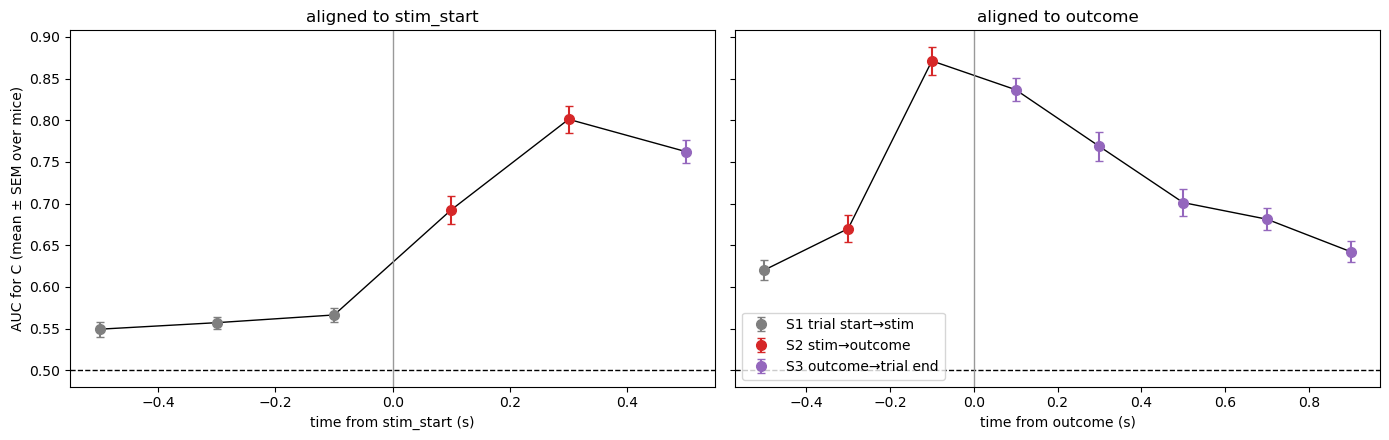

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, ev in zip(axs, q.ALIGN):
    g = tim[tim.event == ev].groupby("t").agg(auc=("auc", "mean"), se=("auc", "sem"), seg=("segment_majority", lambda s: s.mode()[0]))
    ax.plot(g.index, g.auc, color="k", lw=1)
    for s in ["S1", "S2", "S3"]:
        h = g[g.seg == s]
        ax.errorbar(h.index, h.auc, yerr=h.se, fmt="o", ms=7, capsize=3,
                    color=SEG_COLORS[[x for x in SEGS if x.startswith(s)][0]], label=[x for x in SEGS if x.startswith(s)][0])
    ax.axhline(0.5, color="k", ls="--", lw=1); ax.axvline(0, color="0.6", lw=1)
    ax.set(xlabel=f"time from {ev} (s)", title=f"aligned to {ev}")
axs[0].set_ylabel("AUC for C (mean ± SEM over mice)"); axs[1].legend(loc="lower left")
fig.tight_layout()

## 3. Segment comparison

whole: Friedman p = 3.2e-06; S2 vs S1 p = 7.6e-06; S2 vs S3 p = 1.6e-03; S3 vs S1 p = 7.6e-05
equal 0.2s: Friedman p = 8.3e-07; S2 vs S1 p = 7.6e-06; S2 vs S3 p = 5.4e-02; S3 vs S1 p = 7.6e-06


mean AUC  ci_low  ci_high  best in n mice
whole      S1 trial start→stim      0.592   0.577    0.606             0.0
           S2 stim→outcome          0.835   0.802    0.866            14.0
           S3 outcome→trial end     0.733   0.689    0.777             4.0
equal 0.2s S1 trial start→stim      0.568   0.552    0.584             0.0
           S2 stim→outcome          0.848   0.809    0.884            12.0
           S3 outcome→trial end     0.811   0.778    0.841             6.0

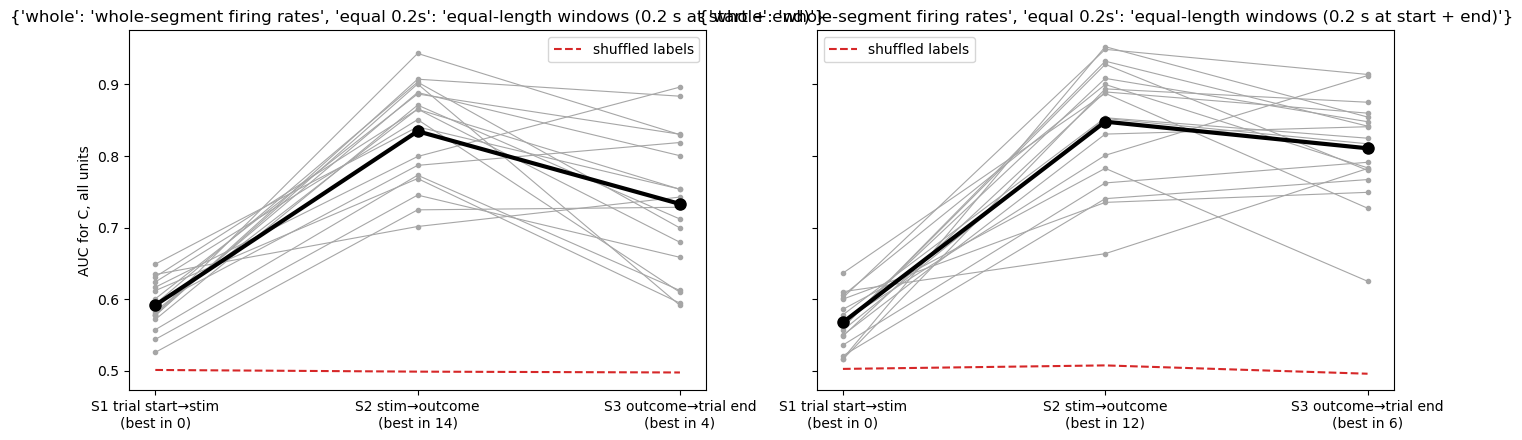

In [4]:
allu = seg[seg.population == "all"]
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
tables = {}
for ax, kind in zip(axs, ["whole", "equal 0.2s"]):
    t = allu[allu.features == kind].pivot(index="mouse", columns="segment", values="auc")[SEGS]
    tables[kind] = t
    for m, row in t.iterrows():
        ax.plot(range(3), row.values, "-o", color="0.65", ms=3, lw=0.8)
    ax.plot(range(3), t.mean().values, "-o", color="k", lw=3, ms=8)
    sh = allu[allu.features == kind].groupby("segment").auc_shuffled.mean()[SEGS]
    ax.plot(range(3), sh.values, "--", color="tab:red", label="shuffled labels")
    best = t.idxmax(axis=1).value_counts()
    ax.set(xticks=range(3), xticklabels=[f"{s}\n(best in {best.get(s, 0)})" for s in SEGS],
           title={"whole": "whole-segment firing rates", "equal 0.2s": "equal-length windows (0.2 s at start + end)"})
    ax.legend()
axs[0].set_ylabel("AUC for C, all units")
fig.tight_layout()

def boot_ci(x, n=10_000, seed=0):
    b = np.random.default_rng(seed).choice(x, size=(n, len(x))).mean(axis=1)
    return np.quantile(b, [0.025, 0.975])

summary = {}
for kind, t in tables.items():
    for s in SEGS:
        lo, hi = boot_ci(t[s].to_numpy())
        summary[(kind, s)] = {"mean AUC": t[s].mean(), "ci_low": lo, "ci_high": hi, "best in n mice": int((t.idxmax(axis=1) == s).sum())}
    print(f"{kind}: Friedman p = {sps.friedmanchisquare(*[t[s] for s in SEGS]).pvalue:.1e}; "
          + "; ".join(f"{SEGS[i][:2]} vs {SEGS[j][:2]} p = {sps.wilcoxon(t[SEGS[i]], t[SEGS[j]]).pvalue:.1e}" for i, j in [(1, 0), (1, 2), (2, 0)]))
pd.DataFrame(summary).T.round(3)

## 4. Each area separately

In [5]:
seg[seg.population != "all"].groupby(["features", "population", "segment"]).auc.mean().unstack()[SEGS].round(3)

segment                S1 trial start→stim  S2 stim→outcome  \
features   population                                         
equal 0.2s 1                         0.537            0.779   
           2                         0.557            0.768   
           3                         0.538            0.664   
whole      1                         0.557            0.763   
           2                         0.589            0.746   
           3                         0.561            0.640   

segment                S3 outcome→trial end  
features   population                        
equal 0.2s 1                          0.743  
           2                          0.743  
           3                          0.646  
whole      1                          0.673  
           2                          0.666  
           3                          0.616

## 5. Why C is not decoded "within each stimulus"

A natural check would be to decode C separately within B = 0 and within B = 1 trials, to remove stimulus information. But by the task structure, **once B is fixed, C and A are the same variable** (choosing C = 2 on a B = 1 trial *is* being correct).
That analysis therefore also decodes the **outcome** (reward vs no reward, and the 1-s timeout of incorrect trials), which is strongest after the outcome (Q11), so it favours S3.
It is shown for completeness, but it can't isolate choice, and it isn't used for the answer.

In [6]:
w = wb.groupby(["features", "mouse", "segment"]).auc.mean().unstack()[SEGS]
w.groupby("features").mean().round(3)

segment,S1 trial start→stim,S2 stim→outcome,S3 outcome→trial end
features,,,
equal 0.2s,0.540,0.804,0.938
whole,0.575,0.770,0.911


## 6. Answer for the questionnaire

In [7]:
from c2p.questionnaire import fill_pdf, record_answer, record_meta

t = tables["whole"]
rows_q = []
for s in SEGS:
    r = summary[("whole", s)]
    rows_q.append((f"{r['mean AUC']:.3f}", f"[{r['ci_low']:.3f}, {r['ci_high']:.3f}]", "ROC AUC"))
pd.DataFrame(rows_q, index=SEGS, columns=["Mean", "95% C.I.", "Units"]).to_csv(RESULTS_DIR / "q12_answer.csv")
te = tables["equal 0.2s"]
peak = tim.groupby(["event", "t"]).auc.mean()
pk_ev, pk_t = peak.idxmax()
expl = (
    f"In the trial table A = 1 exactly when C matches B, so C is the choice (B the stimulus, A correctness); the rare "
    f"C = 1 trials (no choice) were excluded. For each mouse I decoded C (0 vs 2) from all units with cross-validated "
    f"logistic regression and ROC AUC (chance 0.5), separately for each segment, using each unit's firing rate over the "
    f"whole segment. Values are means over mice with bootstrap CIs. C was decoded best during stimulus -> outcome "
    f"(AUC {t[SEGS[1]].mean():.3f} vs {t[SEGS[2]].mean():.3f} after the outcome and {t[SEGS[0]].mean():.3f} before the "
    f"stimulus), in {int((t.idxmax(axis=1) == SEGS[1]).sum())} of 18 mice (Friedman p < 0.001; Wilcoxon p = "
    f"{min(1, 3 * sps.wilcoxon(t[SEGS[1]], t[SEGS[2]]).pvalue):.3f} vs outcome -> trial end). Because segments differ in length, I "
    f"repeated the analysis with equal 0.2-s windows at the start and end of every segment: the ranking was the same "
    f"(AUC {te[SEGS[1]].mean():.3f}, {te[SEGS[2]].mean():.3f}, {te[SEGS[0]].mean():.3f}), although the margin over the "
    f"post-outcome segment was smaller (p = {min(1, 3 * sps.wilcoxon(te[SEGS[1]], te[SEGS[2]]).pvalue):.3f}), and the same ranking held "
    f"in every area separately. Time-resolved decoding peaked in the last 200 ms before the outcome (AUC {peak.max():.2f}) and "
    f"declined after it. Shuffled labels gave 0.50."
)
expl += " Pairwise p-values are Bonferroni-corrected for the three comparisons."
print(len(expl.split()), "words"); print(expl)
record_answer(12, choice=1, rows=rows_q, explanation=expl)   # options: S1, S2, S3, not enough data
record_meta(12, confidence=7, consensus=6)
print(fill_pdf())

192 words
In the trial table A = 1 exactly when C matches B, so C is the choice (B the stimulus, A correctness); the rare C = 1 trials (no choice) were excluded. For each mouse I decoded C (0 vs 2) from all units with cross-validated logistic regression and ROC AUC (chance 0.5), separately for each segment, using each unit's firing rate over the whole segment. Values are means over mice with bootstrap CIs. C was decoded best during stimulus -> outcome (AUC 0.835 vs 0.733 after the outcome and 0.592 before the stimulus), in 14 of 18 mice (Friedman p < 0.001; Wilcoxon p = 0.005 vs outcome -> trial end). Because segments differ in length, I repeated the analysis with equal 0.2-s windows at the start and end of every segment: the ranking was the same (AUC 0.848, 0.811, 0.568), although the margin over the post-outcome segment was smaller (p = 0.162), and the same ranking held in every area separately. Time-resolved decoding peaked in the last 200 ms before the outcome (AUC 0.87) and declin

/home/dariosannino/con2phys/docs/questionnaire_filled.pdf


## Conclusion

**C (the choice) is decoded best during stimulus → outcome.** It peaks in the 200 ms before the outcome, when the choice is executed, and declines after the outcome.
Pre-stimulus decoding is weak but above chance (~0.57–0.59), consistent with choice biases and repeated choices.

**The weak point.** With equal-length windows, the margin over the post-outcome segment is small (p ≈ 0.05), because the first post-outcome window sits right after the peak.